### (2) 데이터 소개

#### 1) 기본 데이터

* 학습 데이터
    * air_2021.csv : 2021년 미세먼지 데이터
    * weather_2021.csv : 2021년 날씨 데이터
* 테스트 데이터
    * air_2022.csv : 2022년 미세먼지 데이터
    * weather_2022.csv : 2022년 날씨 데이터

#### 2) 데이터셋의 변수 소개(weather_2021)

* 증기압: 증기가 고체 또는 액체와 동적 평형 상태에 있을 때 증기의 압력 (증기가 되려는 힘)
* 이슬점 온도: 불포화 상태의 공기가 냉각될 때, 포화 상태에 도달하여 수증기의 응결이 시작되는 온도
* 일조: 일정한 물체나 땅의 겉면에 태양 광선이 비치는 시간 (1시간 중 비율)
* 일사(량): 태양으로부터 오는 태양 복사 에너지가 지표에 닿는 양 (면적당 에너지 량)
* 전운량: 하늘을 육안으로 관측하여 전부 구름일 때 10, 구름이 덮고 있는 하늘의 비율에 따라 0~10
* 중하층운량: 중층과 하층에 있는 구름의 분포량(중하층 구름이 날씨에 영향 주므로 따로 표기)
* 운형(운형약어): 구름의 종류. 약어 코드로 기재됨
* 최저운고: 가장 낮은 구름의 높이
* 현상번호(국내식): 비, 소낙비, 싸락눈, 눈보라 등의 기상현상을 나타낸 코드번호
* 지면온도: 지면 0cm 온도
* 지중온도: 땅 속 온도변수1


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# 한글 깨짐 방지 위해 구글 코랩에 나눔폰트 설치.
import sys
if 'google.colab' in sys.modules:
    !echo 'debconf debconf/frontend select Noninteractive' | debconf-set-selections
    !sudo apt-get -qq -y install fonts-nanum
    import matplotlib.font_manager as fm
    font_files = fm.findSystemFonts(fontpaths=['/usr/share/fonts/truetype/nanum'])
    for fpath in font_files:
        fm.fontManager.addfont(fpath)

Selecting previously unselected package fonts-nanum.
(Reading database ... 126101 files and directories currently installed.)
Preparing to unpack .../fonts-nanum_20200506-1_all.deb ...
Unpacking fonts-nanum (20200506-1) ...
Setting up fonts-nanum (20200506-1) ...
Processing triggers for fontconfig (2.13.1-4.2ubuntu5) ...


# 필요한 라이브러리

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet
from sklearn.tree import DecisionTreeRegressor as DTR
from sklearn.ensemble import RandomForestRegressor as RFR
from sklearn.ensemble import GradientBoostingRegressor as GBR
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import mean_squared_error as mse
from sklearn.metrics import r2_score
from sklearn.metrics import f1_score
from sklearn.metrics import accuracy_score as acc
from sklearn.metrics import recall_score as recall

import joblib

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

In [4]:
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

## 필요한 함수

In [5]:
def vif(dataframe, features):
    """
    다중공선성(VIF)을 계산하는 함수 (const 자동 제거)

    Parameters:
    - dataframe: pd.DataFrame
        입력 데이터프레임
    - features: list of str
        독립 변수(컬럼명) 리스트

    Returns:
    - vif_df: pd.DataFrame
        독립 변수들과 해당하는 VIF 값을 담은 데이터프레임
        (const는 포함되지 않음)
    """
    X = dataframe[features]
    X_const = add_constant(X)

    vif_data = pd.DataFrame()
    vif_data["변수"] = X_const.columns
    vif_data["VIF"] = [variance_inflation_factor(X_const.values, i) for i in range(X_const.shape[1])]

    # const 행 제거
    vif_data = vif_data[vif_data["변수"] != "const"]

    return vif_data


In [6]:


def calculate_vif(X):
    """VIF 계산 (다중공선성 확인용)"""
    vif = pd.DataFrame()
    vif["변수"] = X.columns
    vif["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
    return vif

def stepwise_selection(X, y,
                       initial_list=[],
                       threshold_in=0.05,
                       threshold_out=0.05,
                       vif_threshold=10.0,
                       verbose=True):
    included = list(initial_list)
    while True:
        changed = False

        # forward step
        excluded = list(set(X.columns) - set(included))
        new_pval = pd.Series(index=excluded, dtype=float)
        for new_col in excluded:
            model = sm.OLS(y, sm.add_constant(X[included + [new_col]])).fit()
            new_pval[new_col] = model.pvalues[new_col]
        if not new_pval.empty:
            best_pval = new_pval.min()
            if best_pval < threshold_in:
                best_feature = new_pval.idxmin()
                included.append(best_feature)
                changed = True
                if verbose:
                    print(f'✅ 추가: {best_feature} (p={best_pval:.4f})')

        # backward step
        model = sm.OLS(y, sm.add_constant(X[included])).fit()
        pvalues = model.pvalues.iloc[1:]  # const 제외
        worst_pval = pvalues.max()
        if worst_pval > threshold_out:
            worst_feature = pvalues.idxmax()
            included.remove(worst_feature)
            changed = True
            if verbose:
                print(f'🗑️ 제거: {worst_feature} (p={worst_pval:.4f})')

        if not changed:
            break

    # 최종 모델
    final_model = sm.OLS(y, sm.add_constant(X[included])).fit()

    # VIF 확인
    vif_result = calculate_vif(X[included])
    high_vif = vif_result[vif_result["VIF"] > vif_threshold]
    if not high_vif.empty and verbose:
        print("\n⚠️ 다중공선성 주의 (VIF > threshold):")
        print(high_vif)

    return {
        "선택된 변수": included,
        "최종 모델": final_model,
        "VIF": vif_result
    }


In [7]:
# def calculate_vif(X):
#     """VIF 계산 (다중공선성 확인용)"""
#     vif = pd.DataFrame()
#     vif["변수"] = X.columns
#     vif["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
#     return vif

# def stepwise_selection(X, y,
#                        initial_list=[],
#                        threshold_in=0.05,
#                        threshold_out=0.05,
#                        vif_threshold=10.0,
#                        verbose=True):
#     included = list(initial_list)
#     while True:
#         changed = False

#         # forward step
#         excluded = list(set(X.columns) - set(included))
#         new_pval = pd.Series(index=excluded, dtype=float)
#         for new_col in excluded:
#             model = sm.OLS(y, sm.add_constant(X[included + [new_col]])).fit()
#             new_pval[new_col] = model.pvalues[new_col]
#         if not new_pval.empty:
#             best_pval = new_pval.min()
#             if best_pval < threshold_in:
#                 best_feature = new_pval.idxmin()
#                 included.append(best_feature)
#                 changed = True
#                 if verbose:
#                     print(f'✅ 추가: {best_feature} (p={best_pval:.4f})')

#         # backward step
#         model = sm.OLS(y, sm.add_constant(X[included])).fit()
#         pvalues = model.pvalues.iloc[1:]  # const 제외
#         worst_pval = pvalues.max()
#         if worst_pval > threshold_out:
#             worst_feature = pvalues.idxmax()
#             included.remove(worst_feature)
#             changed = True
#             if verbose:
#                 print(f'🗑️ 제거: {worst_feature} (p={worst_pval:.4f})')

#         if not changed:
#             break

#     # 최종 모델
#     final_model = sm.OLS(y, sm.add_constant(X[included])).fit()

#     # VIF 확인
#     vif_result = calculate_vif(X[included])
#     high_vif = vif_result[vif_result["VIF"] > vif_threshold]
#     if not high_vif.empty and verbose:
#         print("\n⚠️ 다중공선성 주의 (VIF > threshold):")
#         print(high_vif)

#     return {
#         "선택된 변수": included,
#         "최종 모델": final_model,
#         "VIF": vif_result
#     }

# [1] 데이터 셋 불러오기

In [8]:
df_21 = pd.read_csv('/content/drive/MyDrive/AI+X/AI+X선도인재양성프로젝트(중급)/(제공용) 미세먼지 교안, 데이터 및 실습 과제/df_21.csv')
df_22 = pd.read_csv('/content/drive/MyDrive/AI+X/AI+X선도인재양성프로젝트(중급)/(제공용) 미세먼지 교안, 데이터 및 실습 과제/df_22.csv')

In [9]:
df_21.head(3)

,time,지역,SO2,CO,O3,NO2,PM10,PM25,기온(°C),강수량(mm),...,3시간신적설(cm),전운량(10분위),중하층운량(10분위),최저운고(100m ),시정(10m),지면온도(°C),5cm 지중온도(°C),10cm 지중온도(°C),20cm 지중온도(°C),30cm 지중온도(°C)
0,2021-01-01 01:00:00,서울 종로구,0.002,0.5,0.022,0.016,24.0,14.0,-8.7,0.0,...,0.0,0.0,0,999.0,2000,-6.9,-1.0,-0.8,0.3,1.6
1,2021-01-01 02:00:00,서울 종로구,0.002,0.6,0.018,0.020,25.0,14.0,-9.1,0.0,...,0.0,0.0,0,999.0,2000,-7.1,-1.1,-0.8,0.3,1.6
2,2021-01-01 03:00:00,서울 종로구,0.002,0.6,0.013,0.025,27.0,16.0,-9.3,0.0,...,0.0,0.0,0,999.0,2000,-7.3,-1.2,-0.9,0.3,1.6


In [10]:
df_22.head(3)

,time,지역,SO2,CO,O3,NO2,PM10,PM25,기온(°C),강수량(mm),...,3시간신적설(cm),전운량(10분위),중하층운량(10분위),최저운고(100m ),시정(10m),지면온도(°C),5cm 지중온도(°C),10cm 지중온도(°C),20cm 지중온도(°C),30cm 지중온도(°C)
0,2022-01-01 00:00:00,서울 종로구,0.003,0.4,0.026,0.016,20.0,9.0,-8.5,0.0,...,0.0,0,0,999.0,2000,-7.0,-1.0,-1.0,-0.2,1.0
1,2022-01-01 01:00:00,서울 종로구,0.003,0.4,0.026,0.016,23.0,12.0,-9.2,0.0,...,0.0,0,0,999.0,2000,-7.2,-1.1,-1.1,-0.2,1.0
2,2022-01-01 02:00:00,서울 종로구,0.003,0.4,0.022,0.020,20.0,9.0,-9.5,0.0,...,0.0,0,0,999.0,2000,-7.5,-1.3,-1.2,-0.2,1.0


In [11]:
# df_21, df_22에 t+1 시점(다음날) 변수(PM10_1) 추가
df_21['PM10_1']= df_21['PM10'].shift(-1)
df_22['PM10_1']= df_22['PM10'].shift(-1)

In [12]:
df_21.columns

Index(['time', '지역', 'SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25', '기온(°C)',
       '강수량(mm)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)',
       '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '3시간신적설(cm)',
       '전운량(10분위)', '중하층운량(10분위)', '최저운고(100m )', '시정(10m)', '지면온도(°C)',
       '5cm 지중온도(°C)', '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)',
       'PM10_1'],
      dtype='object')

# [2] 다중공선성 확인 및 단계별 선택법 적용

In [13]:
vif(df_21, ['5cm 지중온도(°C)', '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)'])

,변수,VIF
1,5cm 지중온도(°C),2346.420661
2,10cm 지중온도(°C),8610.425222
3,20cm 지중온도(°C),5063.704109
4,30cm 지중온도(°C),801.445165


In [14]:
vif(df_21, ['전운량(10분위)', '중하층운량(10분위)', '최저운고(100m )'])

,변수,VIF
1,전운량(10분위),2.343966
2,중하층운량(10분위),3.404712
3,최저운고(100m ),2.614391


In [15]:
df_21 = df_21.dropna()
df_22 = df_22.dropna()

In [16]:
X = df_21.drop(['time', '지역', 'PM10', 'PM25', 'PM10_1'], axis=1)

In [17]:
result = stepwise_selection(X, df_21['PM10_1'])   # 한 시간 후 미세먼지 예측
result['선택된 변수']

✅ 추가: 시정(10m) (p=0.0000)
✅ 추가: 습도(%) (p=0.0000)
✅ 추가: CO (p=0.0000)
✅ 추가: 강수량(mm) (p=0.0000)
✅ 추가: 현지기압(hPa) (p=0.0000)
✅ 추가: 전운량(10분위) (p=0.0000)
✅ 추가: 증기압(hPa) (p=0.0000)
✅ 추가: 이슬점온도(°C) (p=0.0000)
✅ 추가: 기온(°C) (p=0.0000)
✅ 추가: 최저운고(100m ) (p=0.0000)
✅ 추가: 풍향(16방위) (p=0.0000)
✅ 추가: SO2 (p=0.0001)
✅ 추가: 풍속(m/s) (p=0.0114)
✅ 추가: NO2 (p=0.0111)
✅ 추가: 5cm 지중온도(°C) (p=0.0156)
✅ 추가: 30cm 지중온도(°C) (p=0.0001)
✅ 추가: O3 (p=0.0003)
🗑️ 제거: NO2 (p=0.6043)

⚠️ 다중공선성 주의 (VIF > threshold):
               변수          VIF
0         시정(10m)    23.554296
1           습도(%)   637.064154
2              CO    16.094301
4       현지기압(hPa)  1424.638948
6        증기압(hPa)    41.563855
7       이슬점온도(°C)   453.329823
8          기온(°C)   638.681110
11            SO2    24.206791
13   5cm 지중온도(°C)   442.895715
14  30cm 지중온도(°C)   288.645718


['시정(10m)',
 '습도(%)',
 'CO',
 '강수량(mm)',
 '현지기압(hPa)',
 '전운량(10분위)',
 '증기압(hPa)',
 '이슬점온도(°C)',
 '기온(°C)',
 '최저운고(100m )',
 '풍향(16방위)',
 'SO2',
 '풍속(m/s)',
 '5cm 지중온도(°C)',
 '30cm 지중온도(°C)',
 'O3']

In [18]:
selected_features = result['선택된 변수'].copy()

In [19]:
selected_features

['시정(10m)',
 '습도(%)',
 'CO',
 '강수량(mm)',
 '현지기압(hPa)',
 '전운량(10분위)',
 '증기압(hPa)',
 '이슬점온도(°C)',
 '기온(°C)',
 '최저운고(100m )',
 '풍향(16방위)',
 'SO2',
 '풍속(m/s)',
 '5cm 지중온도(°C)',
 '30cm 지중온도(°C)',
 'O3']

In [20]:
selected_features.remove('5cm 지중온도(°C)')
selected_features.remove('30cm 지중온도(°C)')
selected_features.remove('이슬점온도(°C)')
selected_features.remove('증기압(hPa)')

In [21]:
selected_features

['시정(10m)',
 '습도(%)',
 'CO',
 '강수량(mm)',
 '현지기압(hPa)',
 '전운량(10분위)',
 '기온(°C)',
 '최저운고(100m )',
 '풍향(16방위)',
 'SO2',
 '풍속(m/s)',
 'O3']

In [22]:
vif_result = vif(df_21, selected_features)
vif_result

,변수,VIF
1,시정(10m),1.718524
2,습도(%),2.329334
3,CO,1.983659
4,강수량(mm),1.108507
5,현지기압(hPa),2.505407
6,전운량(10분위),1.969768
7,기온(°C),2.808686
8,최저운고(100m ),1.864235
9,풍향(16방위),1.267668
10,SO2,1.323936


In [23]:
vif_result['변수'].to_list()

['시정(10m)',
 '습도(%)',
 'CO',
 '강수량(mm)',
 '현지기압(hPa)',
 '전운량(10분위)',
 '기온(°C)',
 '최저운고(100m )',
 '풍향(16방위)',
 'SO2',
 '풍속(m/s)',
 'O3']

In [25]:
temp_list = vif_result['변수'].to_list().copy()

In [26]:
temp_list.append('PM10_1')

In [28]:
df_21_corr = df_21[temp_list].corr()
df_21_corr

,시정(10m),습도(%),CO,강수량(mm),현지기압(hPa),전운량(10분위),기온(°C),최저운고(100m ),풍향(16방위),SO2,풍속(m/s),O3,PM10_1
시정(10m),1.000000,-0.501739,-0.319612,-0.255456,0.140281,-0.240725,0.068555,0.156527,0.025460,-0.099724,0.106473,0.158273,-0.354736
습도(%),-0.501739,1.000000,0.064758,0.174899,-0.359593,0.362052,0.145118,-0.304135,-0.200748,-0.162332,-0.285413,-0.310112,-0.062743
CO,-0.319612,0.064758,1.000000,-0.053496,0.341340,-0.049905,-0.394385,0.133074,-0.090331,0.339740,-0.290102,-0.463358,0.317299
강수량(mm),-0.255456,0.174899,-0.053496,1.000000,-0.117995,0.144376,0.034114,-0.094716,-0.028193,-0.043229,0.067254,0.008082,-0.053479
현지기압(hPa),0.140281,-0.359593,0.341340,-0.117995,1.000000,-0.358388,-0.679881,0.358972,0.043709,-0.022978,-0.045875,-0.396239,0.022032
전운량(10분위),-0.240725,0.362052,-0.049905,0.144376,-0.358388,1.000000,0.307381,-0.653915,-0.176756,0.018711,-0.027177,0.028885,-0.099599
기온(°C),0.068555,0.145118,-0.394385,0.034114,-0.679881,0.307381,1.000000,-0.273933,-0.181250,0.047112,-0.070112,0.502834,-0.126854
최저운고(100m ),0.156527,-0.304135,0.133074,-0.094716,0.358972,-0.653915,-0.273933,1.000000,0.074764,0.020789,-0.080656,-0.107343,0.120829
풍향(16방위),0.025460,-0.200748,-0.090331,-0.028193,0.043709,-0.176756,-0.181250,0.074764,1.000000,0.045829,0.173005,0.253343,0.101071
SO2,-0.099724,-0.162332,0.339740,-0.043229,-0.022978,0.018711,0.047112,0.020789,0.045829,1.000000,-0.040919,0.107594,0.217403


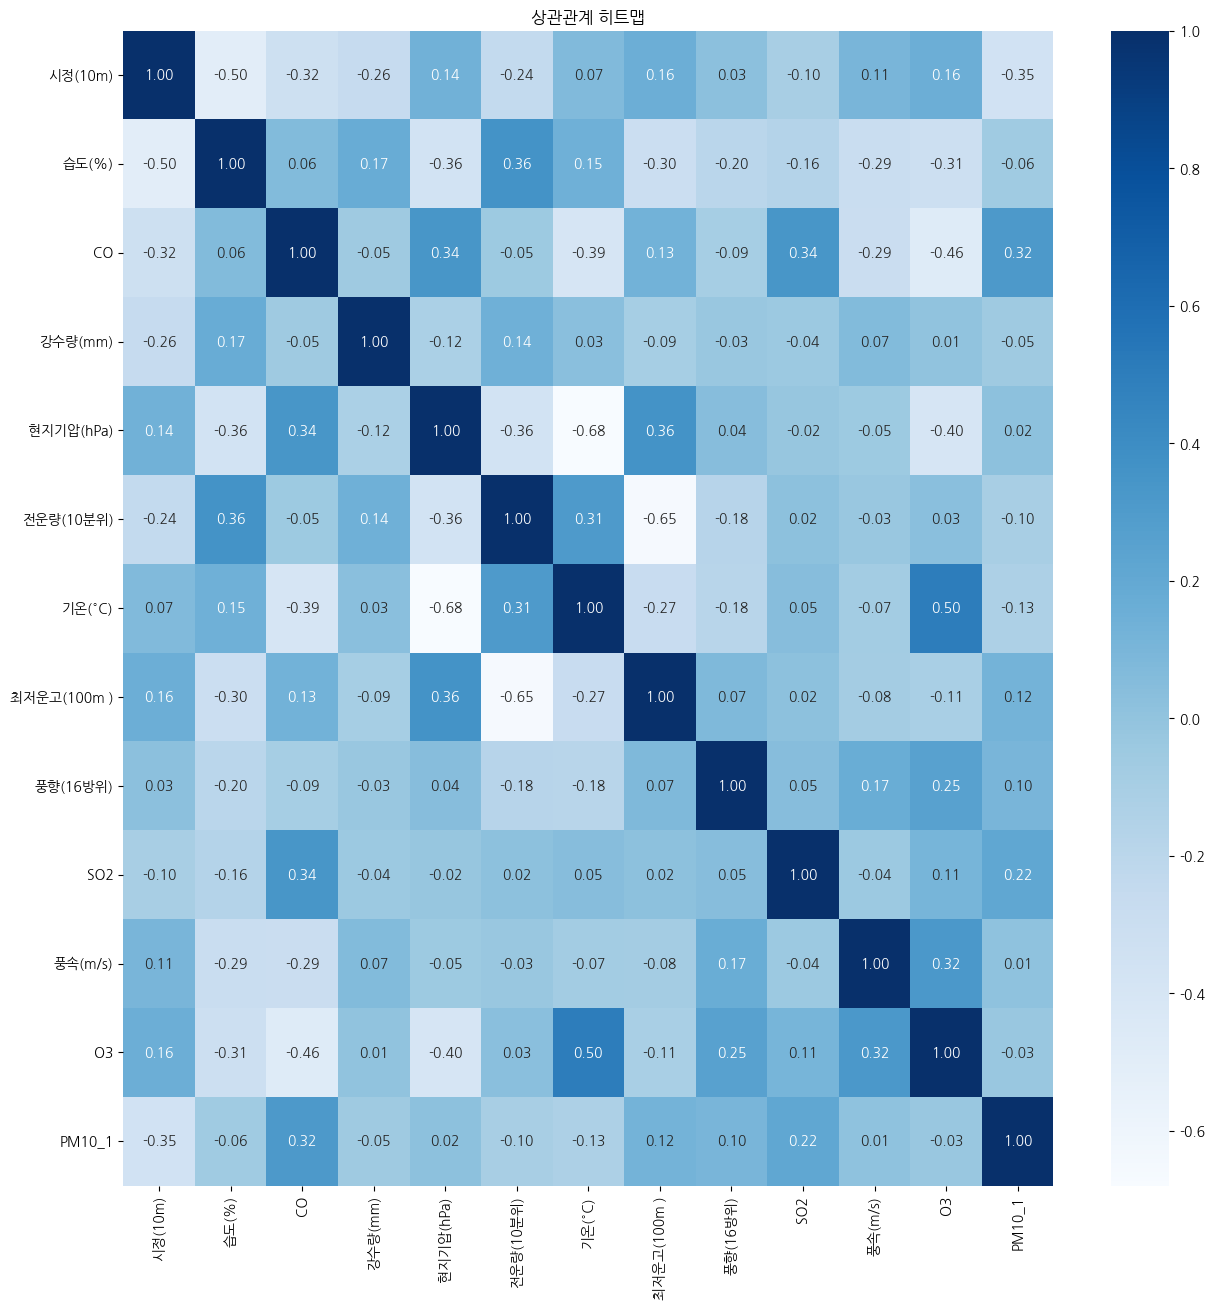

In [29]:
plt.figure(figsize=(15, 15))
sns.heatmap(df_21_corr, annot=True, cmap='Blues', fmt=".2f")
plt.title("상관관계 히트맵")
plt.show()

In [ ]:
selected_features_final = vif_result['변수'].to_list()
selected_features_final

['시정(10m)',
 '습도(%)',
 'CO',
 '강수량(mm)',
 '현지기압(hPa)',
 '전운량(10분위)',
 '기온(°C)',
 '최저운고(100m )',
 '풍향(16방위)',
 'SO2',
 '풍속(m/s)',
 'O3']

# [4] 모델 훈련 및 테스트

## 4-1. 전체 데이터로 돌려보기

#### X, y 설정

In [ ]:
df_21.columns

Index(['time', '지역', 'SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25', '기온(°C)',
       '강수량(mm)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)',
       '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '3시간신적설(cm)',
       '전운량(10분위)', '중하층운량(10분위)', '최저운고(100m )', '시정(10m)', '지면온도(°C)',
       '5cm 지중온도(°C)', '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)',
       'PM10_1'],
      dtype='object')

In [ ]:
X_train = df_21[[ 'SO2', 'CO', 'O3', 'NO2', '기온(°C)',
                  '강수량(mm)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)',
                  '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '3시간신적설(cm)',
                  '전운량(10분위)', '중하층운량(10분위)', '최저운고(100m )', '시정(10m)', '지면온도(°C)',
                  '5cm 지중온도(°C)', '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)']].values
X_test = df_22[[ 'SO2', 'CO', 'O3', 'NO2', '기온(°C)',
                 '강수량(mm)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)',
                 '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '3시간신적설(cm)',
                 '전운량(10분위)', '중하층운량(10분위)', '최저운고(100m )', '시정(10m)', '지면온도(°C)',
                 '5cm 지중온도(°C)', '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)']].values

y_train = df_21['PM10_1']
y_test = df_22['PM10_1']

In [ ]:
sc = StandardScaler()
X_train_sc = sc.fit_transform(X_train)
X_test_sc = sc.transform(X_test)

### LinearRegression

In [ ]:
regressor = LinearRegression()
regressor.fit(X_train_sc, y_train)

LinearRegression()

In [ ]:
y_pred = regressor.predict(X_test_sc)

In [ ]:
y_pred

array([26.7076848 , 25.02173536, 24.99244138, ..., 42.59755043,
       40.4784905 , 23.06491508])

In [ ]:
y_test

,PM10_1
0,23.0
1,20.0
2,20.0
3,19.0
4,24.0
...,...
2154,10.0
2155,11.0
2156,10.0
2157,11.0


In [ ]:
print(np.sqrt(mse(y_test, y_pred))) # RMSE

17.969243778410203


In [ ]:
r2_score(y_test, y_pred)

0.415462197318228

### 랜덤포레스트

In [ ]:
regressor = RFR(random_state=42)
regressor.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [ ]:
y_pred = regressor.predict(X_test)

In [ ]:
print(np.sqrt(mse(y_test, y_pred))) # RMSE

14.59767494033667


In [ ]:
r2_score(y_test, y_pred)

0.61423717026563

### XGBRegressor

In [ ]:
# XGBoost 모델 정의
xgb_model = XGBRegressor(random_state=42)

# 그리드 서치에서 탐색할 하이퍼파라미터 정의
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.1, 0.2],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

# 그리드 서치 수행
grid_search = GridSearchCV(estimator=xgb_model,
                           param_grid=param_grid,
                           scoring='neg_mean_squared_error',
                           cv=5,
                           verbose=1,
                           n_jobs=-1)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 108 candidates, totalling 540 fits


GridSearchCV(cv=5,
             estimator=XGBRegressor(base_score=None, booster=None,
                                    callbacks=None, colsample_bylevel=None,
                                    colsample_bynode=None,
                                    colsample_bytree=None, device=None,
                                    early_stopping_rounds=None,
                                    enable_categorical=False, eval_metric=None,
                                    feature_types=None, gamma=None,
                                    grow_policy=None, importance_type=None,
                                    interaction_constraints=None,
                                    learning_rate=None, m...
                                    min_child_weight=None, missing=nan,
                                    monotone_constraints=None,
                                    multi_strategy=None, n_estimators=None,
                                    n_jobs=None, num_parallel_tree=None,
                                    random_state=42, ...),
             n_jobs=-1,
             param_grid={'colsample_bytree': [0.8, 1.0],
                         'learning_rate': [0.01, 0.1, 0.2],
                         'max_depth': [3, 4, 5], 'n_estimators': [50, 100, 200],
                         'subsample': [0.8, 1.0]},
             scoring='neg_mean_squared_error', verbose=1)

In [ ]:
grid_search.best_params_

{'colsample_bytree': 0.8,
 'learning_rate': 0.2,
 'max_depth': 4,
 'n_estimators': 50,
 'subsample': 1.0}

In [ ]:
xgb_model = grid_search.best_estimator_

In [ ]:
# 4. 예측
y_pred = xgb_model.predict(X_test)

# 5. 성능 평가
print(np.sqrt(mse(y_test, y_pred)))

15.532617217896497


In [ ]:
r2_score(y_test, y_pred)

0.5632405795386795

## 4-2. 일부 변수만 선택해서 모델 훈련

#### X, y 설정

In [ ]:
X_train = df_21[selected_features_final].values
X_test = df_22[selected_features_final].values

In [ ]:
X_train

array([[2.0e+03, 6.8e+01, 5.0e-01, ..., 2.0e-03, 2.4e+00, 2.2e-02],
       [2.0e+03, 6.9e+01, 6.0e-01, ..., 2.0e-03, 1.6e+00, 1.8e-02],
       [2.0e+03, 7.0e+01, 6.0e-01, ..., 2.0e-03, 1.1e+00, 1.3e-02],
       ...,
       [2.0e+03, 3.5e+01, 4.0e-01, ..., 3.0e-03, 4.1e+00, 2.5e-02],
       [2.0e+03, 3.6e+01, 4.0e-01, ..., 3.0e-03, 4.8e+00, 3.0e-02],
       [2.0e+03, 3.7e+01, 4.0e-01, ..., 3.0e-03, 3.0e+00, 3.3e-02]])

In [ ]:
X_test

array([[2.0e+03, 4.1e+01, 4.0e-01, ..., 3.0e-03, 1.9e+00, 2.6e-02],
       [2.0e+03, 4.2e+01, 4.0e-01, ..., 3.0e-03, 1.8e+00, 2.6e-02],
       [2.0e+03, 4.3e+01, 4.0e-01, ..., 3.0e-03, 1.2e+00, 2.2e-02],
       ...,
       [2.0e+03, 4.8e+01, 4.0e-01, ..., 2.0e-03, 2.7e+00, 3.6e-02],
       [2.0e+03, 5.1e+01, 4.0e-01, ..., 2.0e-03, 3.5e+00, 3.2e-02],
       [2.0e+03, 5.8e+01, 3.0e-01, ..., 3.0e-03, 1.9e+00, 3.8e-02]])

In [ ]:
y_train = df_21['PM10_1']
y_test = df_22['PM10_1']
y_train

,PM10_1
0,25.0
1,27.0
2,23.0
3,24.0
4,26.0
...,...
8753,25.0
8754,26.0
8755,27.0
8756,20.0


In [ ]:
sc = StandardScaler()
X_train_sc = sc.fit_transform(X_train)
X_test_sc = sc.transform(X_test)

### LinearRegression

In [ ]:
regressor = LinearRegression()
regressor.fit(X_train_sc, y_train)

LinearRegression()

In [ ]:
y_pred = regressor.predict(X_test_sc)

In [ ]:
y_pred

array([35.68603291, 33.37371748, 31.70854174, ..., 28.90972231,
       26.06255411,  6.66930644])

In [ ]:
y_test

,PM10_1
0,23.0
1,20.0
2,20.0
3,19.0
4,24.0
...,...
2154,10.0
2155,11.0
2156,10.0
2157,11.0


In [ ]:
print(np.sqrt(mse(y_test, y_pred))) # RMSE

18.30403482309438


In [ ]:
r2_score(y_test, y_pred)

0.39347784650266826

### 랜덤포레스트

In [ ]:
regressor = RFR(random_state=42)
regressor.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [ ]:
y_pred = regressor.predict(X_test)

In [ ]:
print(np.sqrt(mse(y_test, y_pred))) # RMSE

15.68398231478788


In [ ]:
r2_score(y_test, y_pred)

0.5546866762094802

### XGBRegressor

In [ ]:
# XGBoost 모델 정의
xgb_model = XGBRegressor(random_state=42)

# 그리드 서치에서 탐색할 하이퍼파라미터 정의
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.1, 0.2],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

# 그리드 서치 수행
grid_search = GridSearchCV(estimator=xgb_model,
                           param_grid=param_grid,
                           scoring='neg_mean_squared_error',
                           cv=5,
                           verbose=1,
                           n_jobs=-1)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 108 candidates, totalling 540 fits


GridSearchCV(cv=5,
             estimator=XGBRegressor(base_score=None, booster=None,
                                    callbacks=None, colsample_bylevel=None,
                                    colsample_bynode=None,
                                    colsample_bytree=None, device=None,
                                    early_stopping_rounds=None,
                                    enable_categorical=False, eval_metric=None,
                                    feature_types=None, gamma=None,
                                    grow_policy=None, importance_type=None,
                                    interaction_constraints=None,
                                    learning_rate=None, m...
                                    min_child_weight=None, missing=nan,
                                    monotone_constraints=None,
                                    multi_strategy=None, n_estimators=None,
                                    n_jobs=None, num_parallel_tree=None,
                                    random_state=42, ...),
             n_jobs=-1,
             param_grid={'colsample_bytree': [0.8, 1.0],
                         'learning_rate': [0.01, 0.1, 0.2],
                         'max_depth': [3, 4, 5], 'n_estimators': [50, 100, 200],
                         'subsample': [0.8, 1.0]},
             scoring='neg_mean_squared_error', verbose=1)

In [ ]:
grid_search.best_params_

{'colsample_bytree': 0.8,
 'learning_rate': 0.1,
 'max_depth': 5,
 'n_estimators': 50,
 'subsample': 0.8}

In [ ]:
xgb_model = grid_search.best_estimator_

In [ ]:
# 4. 예측
y_pred = xgb_model.predict(X_test)

# 5. 성능 평가
print(np.sqrt(mse(y_test, y_pred)))

13.211124834894475


In [ ]:
r2_score(y_test, y_pred)

0.6840396441720992

In [ ]:
y_pred

array([26.356651 , 27.177906 , 24.039024 , ..., 29.04712  , 23.882843 ,
       14.5261545], dtype=float32)

In [ ]:
y_test.values

array([23., 20., 20., ..., 10., 11., 11.])